# Hemoglobin 4HHB with `synced_structure`

Deoxy human hemoglobin is a tetramer of two alpha chains (A, C) and two beta chains (B, D), each holding a heme.
This notebook loads it from RCSB, summarizes the chains, measures the chain interfaces, and draws contact maps and a 3D view.

Requires network access and the package installed: `pip install -e .` from the repository root.

In [1]:
from synced_structure import SyncedStructure

hb = SyncedStructure.from_rcsb("4HHB")
hb.summary()

[PYTHON-INFO] 2026-10-21 18:05:07 | Loaded RCSB structure 4HHB | execution time: 0.71s | max memory: 183.6 MB


,chain_id,auth_chain_id,entity_id,description,external_ref,refseq_id,sequence_length,reference_length,mapped_residues,mapping_fraction
0,A,A,1,Hemoglobin subunit alpha,P69905,P69905,141,141,141,1.0
1,B,B,2,Hemoglobin subunit beta,P68871,P68871,146,146,146,1.0
2,C,C,1,Hemoglobin subunit alpha,P69905,P69905,141,141,141,1.0
3,D,D,2,Hemoglobin subunit beta,P68871,P68871,146,146,146,1.0


Biomolecule content per chain: protein residues, heme ligands, phosphate ions, and water.

In [2]:
hb.moiety_summary.pivot_table(index="chain_id", columns="moiety", values="residues", fill_value=0).astype(int)

moiety,ion,ligand,protein,water
chain_id,,,,
A,0,1,141,56
B,1,1,146,57
C,0,1,141,59
D,1,1,146,49


## Interfaces

Chains in contact, then buried surface area and heavy-atom contacts for every chain pair. The two beta chains (B, D) do not touch in the deoxy state.

In [3]:
hb.chain_contact_partners()

{'A': ['B', 'C', 'D'], 'B': ['A', 'C'], 'C': ['A', 'B', 'D'], 'D': ['A', 'C']}

In [4]:
hb.interface_all()["complex"][["chain_a", "chain_b", "dASA_A2", "n_contacts", "min_dist_A"]]

,chain_a,chain_b,dASA_A2,n_contacts,min_dist_A
0,A,B,1599.24,265,2.664
1,A,C,519.85,62,2.711
2,A,D,1336.77,185,2.383
3,B,C,1322.98,202,2.363
4,B,D,0.00,0,6.125
5,C,D,1650.20,276,2.692


## Contact maps

All four chains on one block map, one color per chain pair, then the alpha1-beta1 interface.

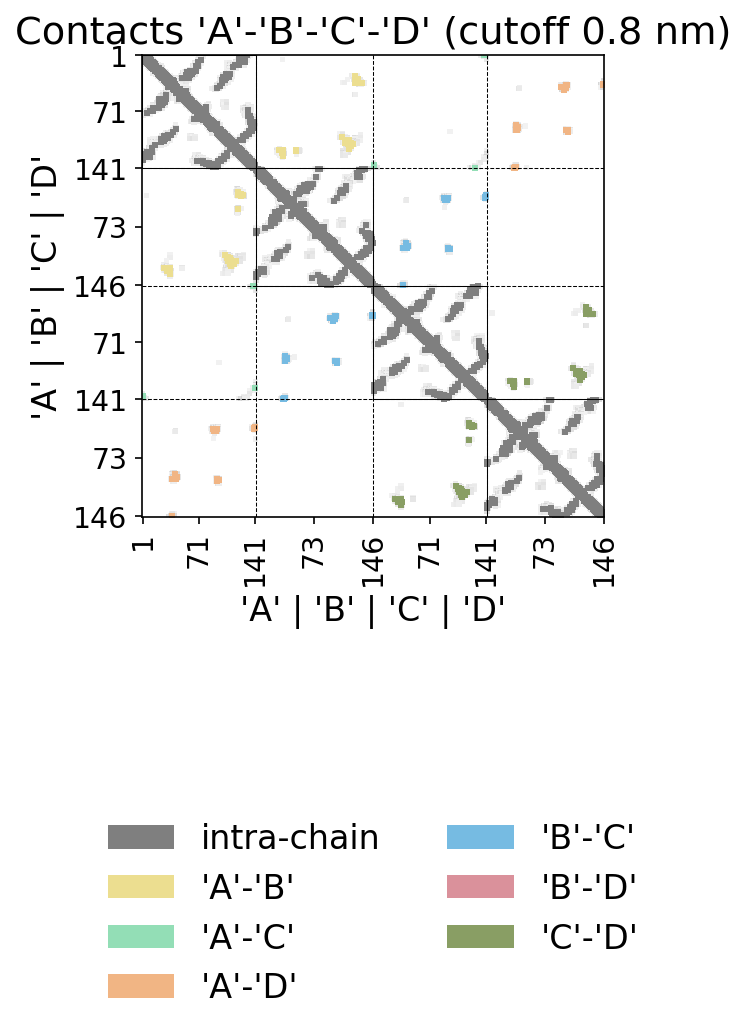

In [5]:
fig, ax = hb.plot_contacts_multi(("A", "B", "C", "D"), n_ticks=3, tick_rotation=90, show_color_legend=True)

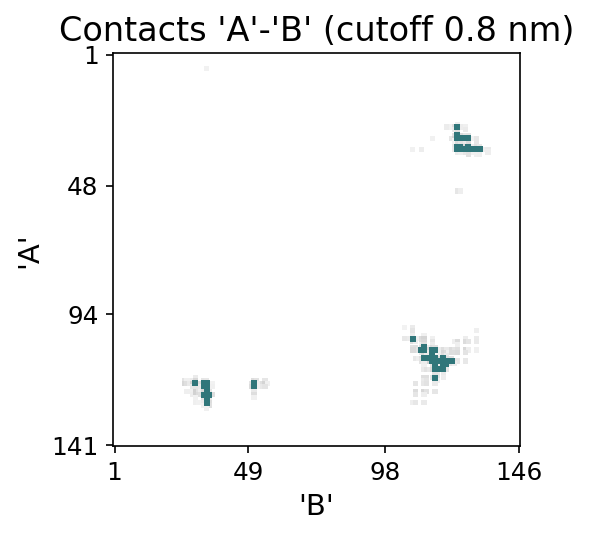

In [6]:
fig, ax = hb.plot_contact_map("A", "B")

## 3D view

Click an atom to label it.

In [7]:
hb.show_structure_3d(title="Deoxy hemoglobin 4HHB")

[PYTHON-INFO] 2026-10-21 18:05:12 | Rendered view of 4HHB at angles (0, 0, 0) | execution time: 0.24s | max memory: 264.0 MB
